In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [7]:
from google.colab import files
uploaded = files.upload()
file_name = next(iter(uploaded))

raw = pd.read_csv(file_name, header=None)
print("Raw shape:", raw.shape)

Saving drsi.csv to drsi (1).csv
Raw shape: (665, 622)


In [8]:
data = raw.iloc[7:, [0, 351]].copy()
data.columns = ["Period", "Retail_Volume_Index"]

data["Period"] = pd.to_datetime(
    data["Period"].astype(str).str.title(),
    format="%Y %b",
    errors="coerce"
)
data["Retail_Volume_Index"] = pd.to_numeric(
    data["Retail_Volume_Index"], errors="coerce"
)

data = (data.dropna()
            .sort_values("Period")
            .loc[lambda x: x["Period"] >= "2021-01-01"]
            .reset_index(drop=True))

print("Cleaned shape:", data.shape)
print("Missing values:", data.isna().sum().to_dict())
display(data.head())
display(data.tail())

Cleaned shape: (69, 2)
Missing values: {'Period': 0, 'Retail_Volume_Index': 0}


,Period,Retail_Volume_Index
0,2021-01-01,100.8
1,2021-02-01,101.9
2,2021-03-01,105.3
3,2021-04-01,114.2
4,2021-05-01,111.2


,Period,Retail_Volume_Index
64,2026-05-01,104.0
65,2026-06-01,104.7
66,2026-07-01,103.9
67,2026-08-01,104.9
68,2026-09-01,104.2


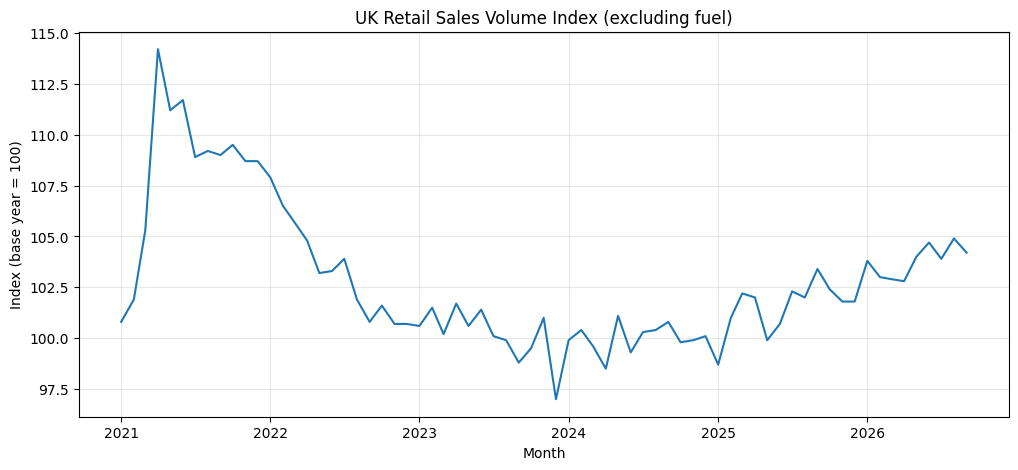

count     69.000000
mean     102.824638
std        3.517076
min       97.000000
25%      100.400000
50%      101.800000
75%      104.000000
max      114.200000
Name: Retail_Volume_Index, dtype: float64


In [9]:
plt.figure(figsize=(12, 5))
plt.plot(data["Period"], data["Retail_Volume_Index"])
plt.title("UK Retail Sales Volume Index (excluding fuel)")
plt.xlabel("Month")
plt.ylabel("Index (base year = 100)")
plt.grid(True, alpha=0.3)
plt.show()

print(data["Retail_Volume_Index"].describe())

In [10]:
ts = data.set_index("Period")["Retail_Volume_Index"].asfreq("MS")
train = ts.iloc[:-12]
test = ts.iloc[-12:]
print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 57
Testing observations: 12


MAE: 0.88 index points
RMSE: 1.08 index points


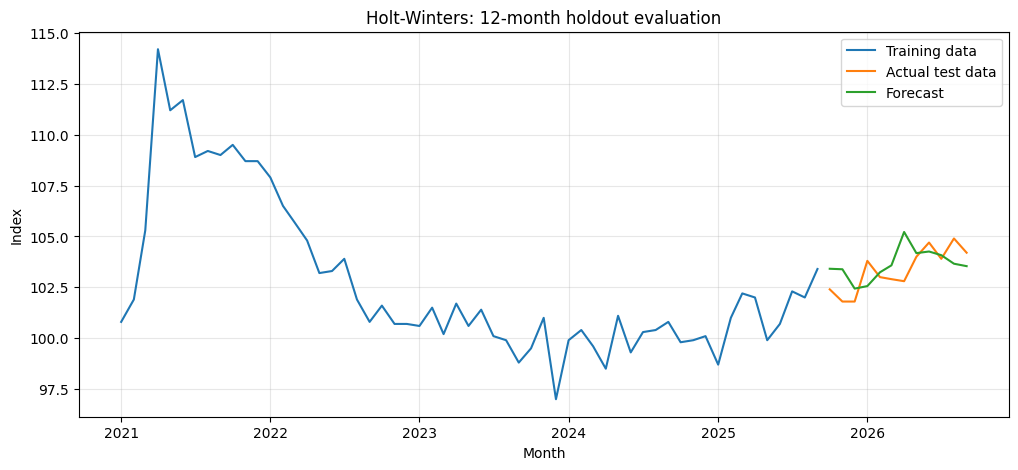

In [11]:
model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True)

test_forecast = model.forecast(12)
mae = mean_absolute_error(test, test_forecast)
rmse = mean_squared_error(test, test_forecast) ** 0.5

print(f"MAE: {mae:.2f} index points")
print(f"RMSE: {rmse:.2f} index points")

plt.figure(figsize=(12, 5))
plt.plot(train.index, train, label="Training data")
plt.plot(test.index, test, label="Actual test data")
plt.plot(test_forecast.index, test_forecast, label="Forecast")
plt.title("Holt-Winters: 12-month holdout evaluation")
plt.xlabel("Month")
plt.ylabel("Index")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

,Forecast_Period,Forecast_Retail_Volume_Index
0,2026-10-01,104.26
1,2026-11-01,104.12
2,2026-12-01,103.36
3,2027-01-01,103.84
4,2027-02-01,104.27
5,2027-03-01,104.54


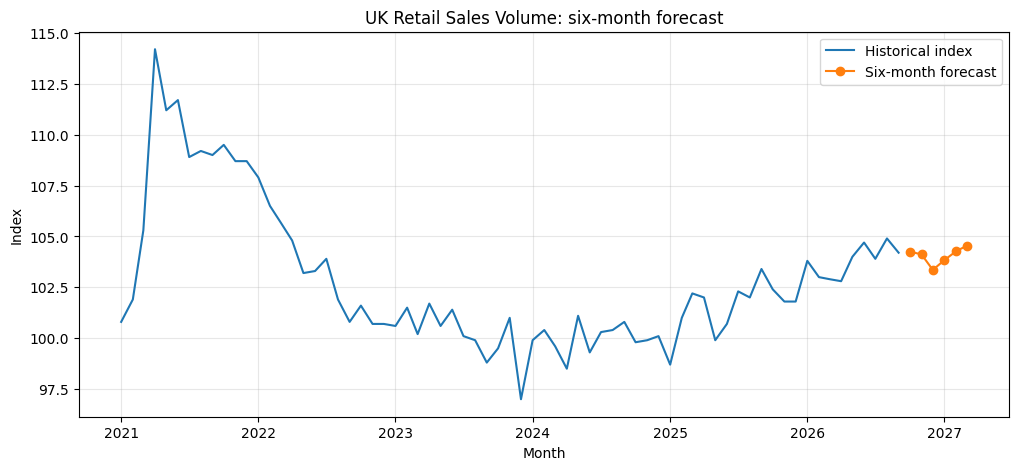

In [12]:
final_model = ExponentialSmoothing(
    ts,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit(optimized=True)

future_forecast = final_model.forecast(6)
forecast_df = future_forecast.rename(
    "Forecast_Retail_Volume_Index"
).reset_index()
forecast_df.columns = ["Forecast_Period", "Forecast_Retail_Volume_Index"]
display(forecast_df.round(2))

plt.figure(figsize=(12, 5))
plt.plot(ts.index, ts, label="Historical index")
plt.plot(future_forecast.index, future_forecast, marker="o", label="Six-month forecast")
plt.title("UK Retail Sales Volume: six-month forecast")
plt.xlabel("Month")
plt.ylabel("Index")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
data.to_csv("UK_Retail_Sales_Cleaned.csv", index=False)
forecast_df.to_csv("UK_Retail_Sales_Forecast.csv", index=False)

from google.colab import files
files.download("UK_Retail_Sales_Cleaned.csv")
files.download("UK_Retail_Sales_Forecast.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>